<a href="https://colab.research.google.com/github/hlacquement6-dotcom/customer-churn-eda/blob/main/customer_churn_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

# Convert TotalCharges and drop missing rows
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['TotalCharges'])

# Check target distribution
df['Churn'].value_counts(normalize=True) * 100

,proportion
Churn,
No,73.421502
Yes,26.578498


In [7]:
import sqlite3

conn = sqlite3.connect(':memory:')
df.to_sql('customers', conn, index=False, if_exists='replace')

query = """
    SELECT
        Churn,
        COUNT(*) AS TotalCustomers,
        ROUND(AVG(MonthlyCharges), 2) AS AvgMonthlyCharges,
        ROUND(AVG(tenure), 1) AS AvgTenureMonths
    FROM customers
    GROUP BY Churn;
"""

pd.read_sql(query, conn)

,Churn,TotalCustomers,AvgMonthlyCharges,AvgTenureMonths
0,No,5163,61.31,37.7
1,Yes,1869,74.44,18.0


In [8]:
contract_query = """
    SELECT
        Contract,
        COUNT(*) AS TotalCustomers,
        SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS ChurnedCount,
        ROUND(CAST(SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS REAL) / COUNT(*) * 100, 2) AS ChurnRatePercentage
    FROM customers
    GROUP BY Contract;
"""

contract_result = pd.read_sql(contract_query, conn)
display(contract_result)

,Contract,TotalCustomers,ChurnedCount,ChurnRatePercentage
0,Month-to-month,3875,1655,42.71
1,One year,1472,166,11.28
2,Two year,1685,48,2.85


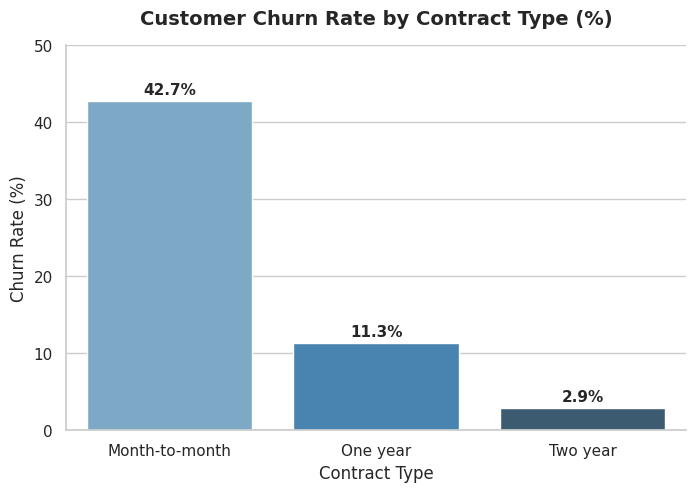

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x='Contract',
    y='ChurnRatePercentage',
    data=contract_result,
    hue='Contract',
    palette='Blues_d',
    legend=False
)

plt.title('Customer Churn Rate by Contract Type (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Contract Type', fontsize=12)
plt.ylabel('Churn Rate (%)', fontsize=12)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontsize=11, fontweight='semibold')

plt.ylim(0, 50)
sns.despine()
plt.show()